# Movie Dataset

In [37]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

# Read data

In [42]:
#Read the document and the head of the data 
df=pd.read_csv("movie_metadata.csv")
df.head()

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000.0
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0.0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000.0
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000.0
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0.0


In [44]:
#To know how many rows and columns
df.shape

(1608, 28)

In [46]:
#To know the name of the columns and know which one could I delete it
df.columns

Index(['color', 'director_name', 'num_critic_for_reviews', 'duration',
       'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name',
       'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name',
       'movie_title', 'num_voted_users', 'cast_total_facebook_likes',
       'actor_3_name', 'facenumber_in_poster', 'plot_keywords',
       'movie_imdb_link', 'num_user_for_reviews', 'language', 'country',
       'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes',
       'imdb_score', 'aspect_ratio', 'movie_facebook_likes'],
      dtype='str')

In [48]:
#To know the type of the data in the dataset / str = text / float64 = decimel / int = #s
df.dtypes

color                            str
director_name                    str
num_critic_for_reviews       float64
duration                     float64
director_facebook_likes      float64
actor_3_facebook_likes       float64
actor_2_name                     str
actor_1_facebook_likes       float64
gross                        float64
genres                           str
actor_1_name                     str
movie_title                      str
num_voted_users              float64
cast_total_facebook_likes    float64
actor_3_name                     str
facenumber_in_poster         float64
plot_keywords                    str
movie_imdb_link                  str
num_user_for_reviews         float64
language                         str
country                          str
content_rating                   str
budget                       float64
title_year                   float64
actor_2_facebook_likes       float64
imdb_score                   float64
aspect_ratio                 float64
m

# Clean the data

In [51]:
#Check null values
df.isnull().sum()

color                         3
director_name                27
num_critic_for_reviews        3
duration                      4
director_facebook_likes      27
actor_3_facebook_likes        3
actor_2_name                  2
actor_1_facebook_likes        1
gross                        69
genres                        1
actor_1_name                  1
movie_title                   1
num_voted_users               1
cast_total_facebook_likes     1
actor_3_name                  3
facenumber_in_poster          3
plot_keywords                13
movie_imdb_link               1
num_user_for_reviews          4
language                      3
country                       3
content_rating               24
budget                       64
title_year                   30
actor_2_facebook_likes        2
imdb_score                    1
aspect_ratio                 19
movie_facebook_likes          1
dtype: int64

In [53]:
#Unique values of columns
a=df["facenumber_in_poster"].unique()
b=df["plot_keywords"].unique()
c=df["movie_imdb_link"].unique()
d=df["aspect_ratio"].unique()
print(a,b,c,d)

[ 0.  1.  4.  3.  2.  6.  7.  5.  8. nan 10. 15.  9. 11. 12. 31.] <StringArray>
[                                                         'avatar|future|marine|native|paraplegic',
                                    'goddess|marriage ceremony|marriage proposal|pirate|singapore',
                                                             'bomb|espionage|sequel|spy|terrorist',
                                'deception|imprisonment|lawlessness|police officer|terrorist plot',
                                                                                               nan,
                                              'alien|american civil war|male nipple|mars|princess',
                                                       'sandman|spider man|symbiote|venom|villain',
                                            '17th century|based on fairy tale|disney|flower|tower',
 'artificial intelligence|based on comic book|captain america|marvel cinematic universe|superhero',
                    

In [55]:
#Describe summarize of the columns
e=df["facenumber_in_poster"].describe()
f=df["plot_keywords"].describe()
g=df["movie_imdb_link"].describe()
h=df["aspect_ratio"].describe()
print(e,f,g,h,)

count    1605.000000
mean        1.327103
std         1.913867
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max        31.000000
Name: facenumber_in_poster, dtype: float64 count                                                  1595
unique                                                 1579
top       eighteen wheeler|illegal street racing|truck|t...
freq                                                      3
Name: plot_keywords, dtype: object count                                                  1607
unique                                                 1591
top       http://www.imdb.com/title/tt0232500/?ref_=fn_t...
freq                                                      3
Name: movie_imdb_link, dtype: object count    1589.000000
mean        2.271592
std         1.123912
min         1.330000
25%         1.850000
50%         2.350000
75%         2.350000
max        16.000000
Name: aspect_ratio, dtype: float64


In [57]:
#Delete the facenumber_in_poster
i=df.drop(["facenumber_in_poster"], axis=1, inplace=True)
j=df.drop(["plot_keywords"], axis=1, inplace=True)
k=df.drop(["movie_imdb_link"], axis=1, inplace=True)
l=df.drop(["aspect_ratio"], axis=1, inplace=True)
print(i,j,k,l)

None None None None


In [59]:
#To know if I delete the column facenumber_in_poster its not important
df.columns

Index(['color', 'director_name', 'num_critic_for_reviews', 'duration',
       'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name',
       'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name',
       'movie_title', 'num_voted_users', 'cast_total_facebook_likes',
       'actor_3_name', 'num_user_for_reviews', 'language', 'country',
       'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes',
       'imdb_score', 'movie_facebook_likes'],
      dtype='str')

In [61]:
#Convert NAN per columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1608 entries, 0 to 1607
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      1605 non-null   str    
 1   director_name              1581 non-null   str    
 2   num_critic_for_reviews     1605 non-null   float64
 3   duration                   1604 non-null   float64
 4   director_facebook_likes    1581 non-null   float64
 5   actor_3_facebook_likes     1605 non-null   float64
 6   actor_2_name               1606 non-null   str    
 7   actor_1_facebook_likes     1607 non-null   float64
 8   gross                      1539 non-null   float64
 9   genres                     1607 non-null   str    
 10  actor_1_name               1607 non-null   str    
 11  movie_title                1607 non-null   str    
 12  num_voted_users            1607 non-null   float64
 13  cast_total_facebook_likes  1607 non-null   float64
 14  act

In [63]:
#NAN to 0
df=df.fillna(0)

In [65]:
#To convert 0.0 in 0
df = df.astype({'num_critic_for_reviews': 'Int64',
                'director_facebook_likes': 'Int64',
                'actor_3_facebook_likes': 'Int64',
                'actor_1_facebook_likes': 'Int64',
                'num_voted_users': 'Int64',
                'cast_total_facebook_likes': 'Int64',
                'num_user_for_reviews': 'Int64',
                'title_year': 'Int64',
                'actor_2_facebook_likes': 'Int64',
                'movie_facebook_likes': 'Int64'})

In [67]:
#To check the changes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1608 entries, 0 to 1607
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      1608 non-null   object 
 1   director_name              1608 non-null   object 
 2   num_critic_for_reviews     1608 non-null   Int64  
 3   duration                   1608 non-null   float64
 4   director_facebook_likes    1608 non-null   Int64  
 5   actor_3_facebook_likes     1608 non-null   Int64  
 6   actor_2_name               1608 non-null   object 
 7   actor_1_facebook_likes     1608 non-null   Int64  
 8   gross                      1608 non-null   float64
 9   genres                     1608 non-null   object 
 10  actor_1_name               1608 non-null   object 
 11  movie_title                1608 non-null   object 
 12  num_voted_users            1608 non-null   Int64  
 13  cast_total_facebook_likes  1608 non-null   Int64  
 14  act

# Exploratory Data Analysis and Descriptive Statistics

## Measures of Cental Tendency

### Mean, Media and Mode

In [72]:
#Mean of every columns (conditional)
cols = df.columns.tolist()
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        mean = df[i].mean()
        print(f"Mean of {i}: {mean}")

Mean of num_critic_for_reviews: 198.92101990049753
Mean of duration: 114.70584577114428
Mean of director_facebook_likes: 1109.120024875622
Mean of actor_3_facebook_likes: 1117.7767412935323
Mean of actor_1_facebook_likes: 9770.618781094527
Mean of gross: 84413004.06840795
Mean of num_voted_users: 147197.21268656716
Mean of cast_total_facebook_likes: 15033.42723880597
Mean of num_user_for_reviews: 438.99564676616916
Mean of budget: 70015353.32587065
Mean of title_year: 1967.351368159204
Mean of actor_2_facebook_likes: 2870.907338308458
Mean of imdb_score: 6.450808457711442
Mean of movie_facebook_likes: 13097.651741293532


In [74]:
#Median of every columns
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        median = df[i].median()
        print(f"Median of {i}: {median}")

Median of num_critic_for_reviews: 169.0
Median of duration: 112.0
Median of director_facebook_likes: 87.0
Median of actor_3_facebook_likes: 532.0
Median of actor_1_facebook_likes: 8000.0
Median of gross: 58653627.0
Median of num_voted_users: 87449.0
Median of cast_total_facebook_likes: 11294.0
Median of num_user_for_reviews: 282.5
Median of budget: 55000000.0
Median of title_year: 2005.0
Median of actor_2_facebook_likes: 826.0
Median of imdb_score: 6.5
Median of movie_facebook_likes: 352.5


In [76]:
#Mode of every columns, context has 17 mode cause its reapeat the data
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        mode = df[i].mode(0)
        print(f"Mode of {i}: {mode}")

Mode of num_critic_for_reviews: 0    117
1    125
Name: num_critic_for_reviews, dtype: Int64
Mode of duration: 0    101.0
Name: duration, dtype: float64
Mode of director_facebook_likes: 0    0
Name: director_facebook_likes, dtype: Int64
Mode of actor_3_facebook_likes: 0    1000
Name: actor_3_facebook_likes, dtype: Int64
Mode of actor_1_facebook_likes: 0    1000
Name: actor_1_facebook_likes, dtype: Int64
Mode of gross: 0    0.0
Name: gross, dtype: float64
Mode of num_voted_users: 0        374
1       2138
2      20201
3      28618
4      39956
5      42372
6      46239
7      68417
8     101178
9     103589
10    110486
11    115687
12    124765
13    185394
14    240241
15    272223
16    995415
Name: num_voted_users, dtype: Int64
Mode of cast_total_facebook_likes: 0     1261
1     3580
2     9152
3    45327
Name: cast_total_facebook_likes, dtype: Int64
Mode of num_user_for_reviews: 0    289
Name: num_user_for_reviews, dtype: Int64
Mode of budget: 0    40000000.0
Name: budget, dtype: f

### Plot the distribution

<Axes: xlabel='num_critic_for_reviews'>

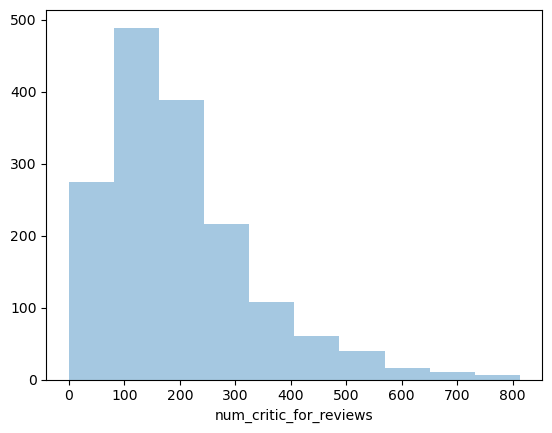

In [79]:
# Plot the distribution for column + delete warnings
import warnings
warnings.filterwarnings("ignore")

data = df["num_critic_for_reviews"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"num_critic_for_reviews"})

<Axes: xlabel='duration'>

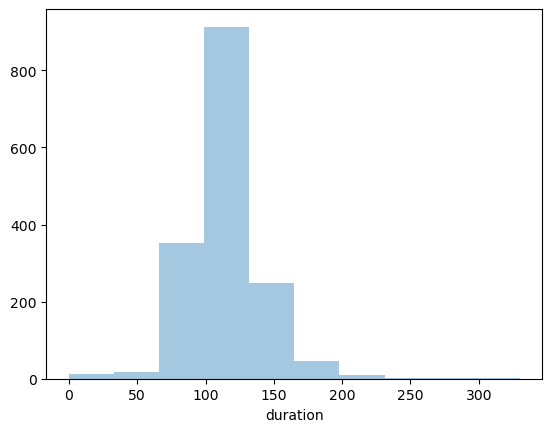

In [81]:
data = df["duration"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"duration"})

<Axes: xlabel='director_facebook_likes'>

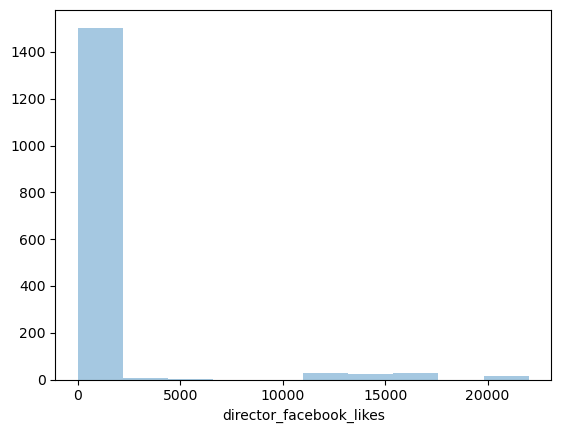

In [83]:
data = df["director_facebook_likes"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"director_facebook_likes"})

<Axes: xlabel='actor_3_facebook_likes'>

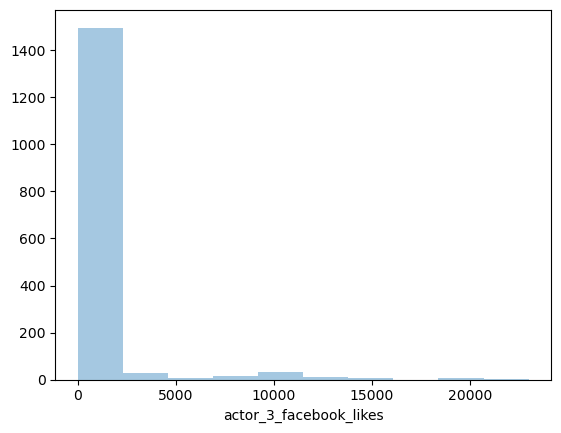

In [85]:
data = df["actor_3_facebook_likes"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"actor_3_facebook_likes"})

<Axes: xlabel='actor_1_facebook_likes'>

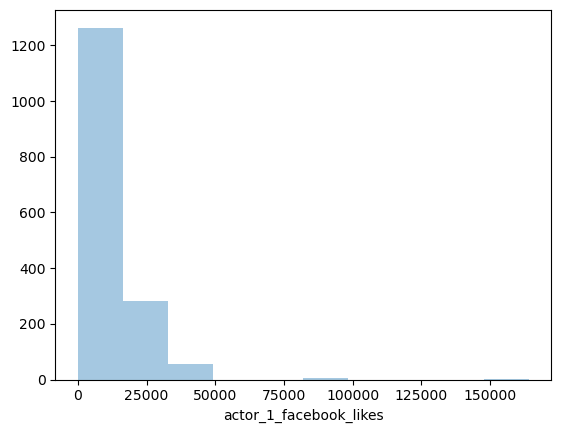

In [87]:
data = df["actor_1_facebook_likes"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"actor_1_facebook_likes"})

<Axes: xlabel='gross'>

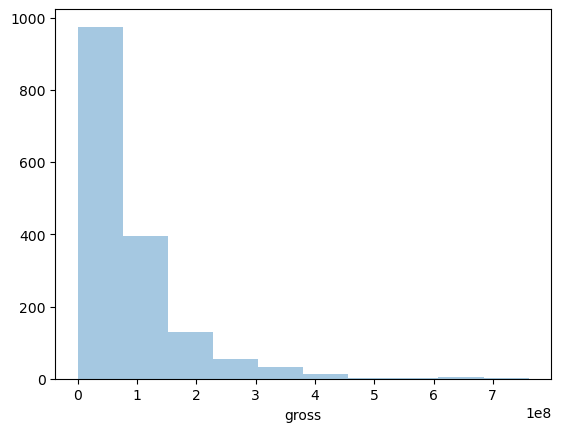

In [89]:
data = df["gross"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"gross"})

<Axes: xlabel='num_voted_users'>

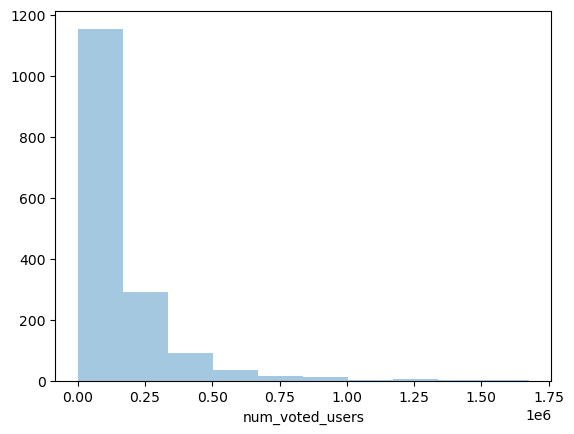

In [91]:
data = df["num_voted_users"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"num_voted_users"})

<Axes: xlabel='cast_total_facebook_likes'>

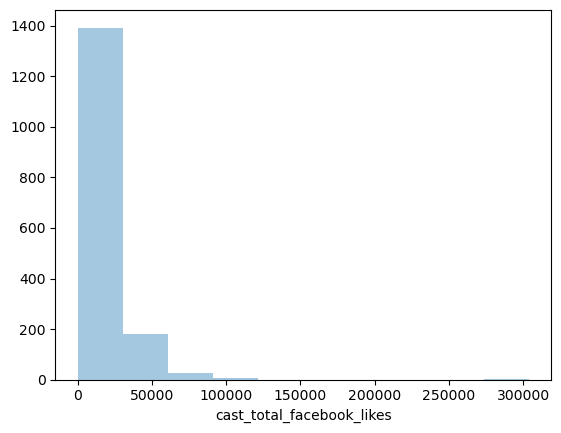

In [93]:
data = df["cast_total_facebook_likes"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"cast_total_facebook_likes"})

<Axes: xlabel='num_user_for_reviews'>

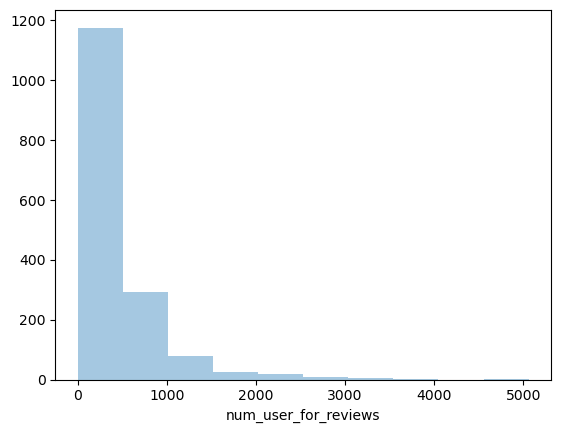

In [95]:
data = df["num_user_for_reviews"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"num_user_for_reviews"})

<Axes: xlabel='budget'>

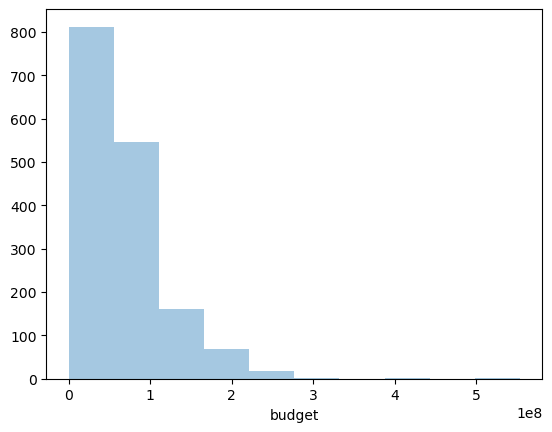

In [97]:
data = df["budget"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"budget"})

<Axes: xlabel='title_year'>

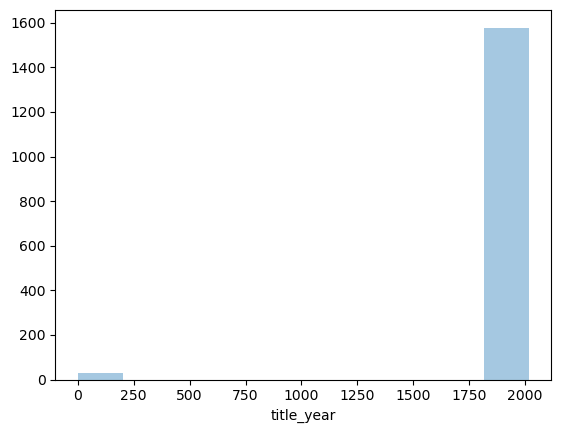

In [99]:
data = df["title_year"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"title_year"})

<Axes: xlabel='actor_2_facebook_likes'>

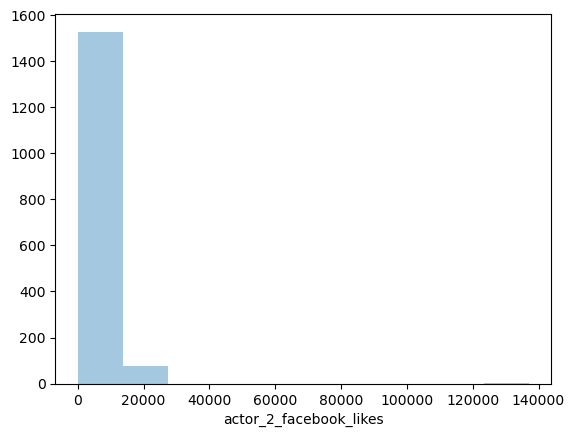

In [101]:
data = df["actor_2_facebook_likes"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"actor_2_facebook_likes"})

<Axes: xlabel='imdb_score'>

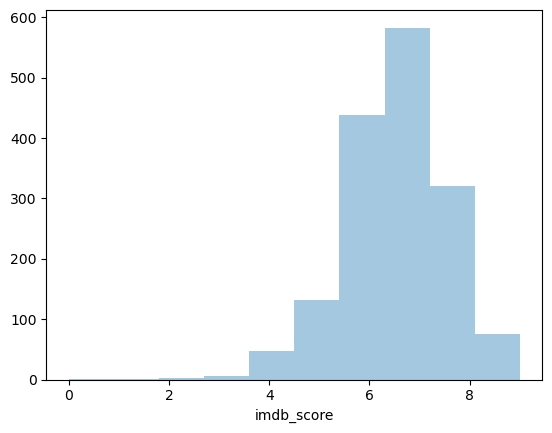

In [103]:
data = df["imdb_score"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"imdb_score"})

<Axes: xlabel='movie_facebook_likes'>

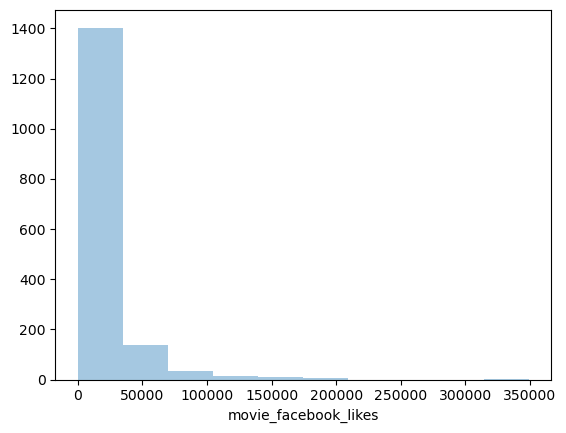

In [105]:
data = df["movie_facebook_likes"]
sns.distplot(data, bins=10, hist=True, kde=False, label = {"movie_facebook_likes"})

# Measures of Dispersion/Variability

## Computation of measures of dispersion or variability

### Minimum value

In [110]:
#Minimum value on the loop
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        minimum = df[i].min()
        print(f"Minimum of {i}: {minimum}")

Minimum of num_critic_for_reviews: 0
Minimum of duration: 0.0
Minimum of director_facebook_likes: 0
Minimum of actor_3_facebook_likes: 0
Minimum of actor_1_facebook_likes: 0
Minimum of gross: 0.0
Minimum of num_voted_users: 0
Minimum of cast_total_facebook_likes: 0
Minimum of num_user_for_reviews: 0
Minimum of budget: 0.0
Minimum of title_year: 0
Minimum of actor_2_facebook_likes: 0
Minimum of imdb_score: 0.0
Minimum of movie_facebook_likes: 0


### Maximum value

In [113]:
#Maximum value on the loop
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        maximum = df[i].max()
        print(f"Maximum of {i}: {maximum}")

Maximum of num_critic_for_reviews: 813
Maximum of duration: 330.0
Maximum of director_facebook_likes: 22000
Maximum of actor_3_facebook_likes: 23000
Maximum of actor_1_facebook_likes: 164000
Maximum of gross: 760505847.0
Maximum of num_voted_users: 1676169
Maximum of cast_total_facebook_likes: 303717
Maximum of num_user_for_reviews: 5060
Maximum of budget: 553632000.0
Maximum of title_year: 2016
Maximum of actor_2_facebook_likes: 137000
Maximum of imdb_score: 9.0
Maximum of movie_facebook_likes: 349000


### Range

In [116]:
#Range value on the loop
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        range = df[i].max() - df[i].min()
        print(f"Range of {i}: {range}")

Range of num_critic_for_reviews: 813
Range of duration: 330.0
Range of director_facebook_likes: 22000
Range of actor_3_facebook_likes: 23000
Range of actor_1_facebook_likes: 164000
Range of gross: 760505847.0
Range of num_voted_users: 1676169
Range of cast_total_facebook_likes: 303717
Range of num_user_for_reviews: 5060
Range of budget: 553632000.0
Range of title_year: 2016
Range of actor_2_facebook_likes: 137000
Range of imdb_score: 9.0
Range of movie_facebook_likes: 349000


### Variance

In [119]:
#Variance value on the loop
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        variance = df[i].var()
        print(f"Variance of {i}: {variance}")

Variance of num_critic_for_reviews: 18178.634081846525
Variance of duration: 721.2942532979163
Variance of director_facebook_likes: 13849105.090127692
Variance of actor_3_facebook_likes: 6589018.4012757465
Variance of actor_1_facebook_likes: 129533248.05308825
Variance of gross: 7578596293055060.0
Variance of num_voted_users: 31505529406.002033
Variance of cast_total_facebook_likes: 319023382.30957496
Variance of num_user_for_reviews: 244907.59985658206
Variance of budget: 2433180793416637.5
Variance of title_year: 73688.153377094
Variance of actor_2_facebook_likes: 33341752.28076752
Variance of imdb_score: 1.020907871191646
Variance of movie_facebook_likes: 735693365.9707375


### Standard deviation

In [122]:
#Standard value on the loop
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        standard_deviation = df[i].std()
        print(f"Standard Deviation of {i}: {standard_deviation}")

Standard Deviation of num_critic_for_reviews: 134.82816501698198
Standard Deviation of duration: 26.856921887995956
Standard Deviation of director_facebook_likes: 3721.4385780404455
Standard Deviation of actor_3_facebook_likes: 2566.9083351915287
Standard Deviation of actor_1_facebook_likes: 11381.267418573743
Standard Deviation of gross: 87055133.63986675
Standard Deviation of num_voted_users: 177497.9701461457
Standard Deviation of cast_total_facebook_likes: 17861.225666498223
Standard Deviation of num_user_for_reviews: 494.88139978845646
Standard Deviation of budget: 49327282.44507939
Standard Deviation of title_year: 271.45561953493245
Standard Deviation of actor_2_facebook_likes: 5774.231748100133
Standard Deviation of imdb_score: 1.0103998570821584
Standard Deviation of movie_facebook_likes: 27123.668003622544


### Q1, Q3, Interquantile Range

In [125]:
#Q3 + Q1 + Interquantile Range value on the loop
for i in cols: # por cada elemento en la lista
    if df[i].dtype == 'object': #si cumple esta condicion no haga nada
        continue
    else: # y si no
        Q3 = df[i].quantile(0.75)
        print(f"Quantile 3 of {i}: {Q3}")
        Q1 = df[i].quantile(0.25)
        print(f"Quantile 1 of {i}: {Q1}")
        R = Q3  - Q1
        print(f"Interquantile Range of {i}: {R}")

Quantile 3 of num_critic_for_reviews: 261.25
Quantile 1 of num_critic_for_reviews: 103.0
Interquantile Range of num_critic_for_reviews: 158.25
Quantile 3 of duration: 127.0
Quantile 1 of duration: 99.0
Interquantile Range of duration: 28.0
Quantile 3 of director_facebook_likes: 309.0
Quantile 1 of director_facebook_likes: 13.0
Interquantile Range of director_facebook_likes: 296.0
Quantile 3 of actor_3_facebook_likes: 808.0
Quantile 1 of actor_3_facebook_likes: 270.5
Interquantile Range of actor_3_facebook_likes: 537.5
Quantile 3 of actor_1_facebook_likes: 15000.0
Quantile 1 of actor_1_facebook_likes: 919.0
Interquantile Range of actor_1_facebook_likes: 14081.0
Quantile 3 of gross: 112964760.75
Quantile 1 of gross: 27792003.5
Interquantile Range of gross: 85172757.25
Quantile 3 of num_voted_users: 185352.0
Quantile 1 of num_voted_users: 40516.5
Interquantile Range of num_voted_users: 144835.5
Quantile 3 of cast_total_facebook_likes: 20965.25
Quantile 1 of cast_total_facebook_likes: 2689

### Draw Boxplot

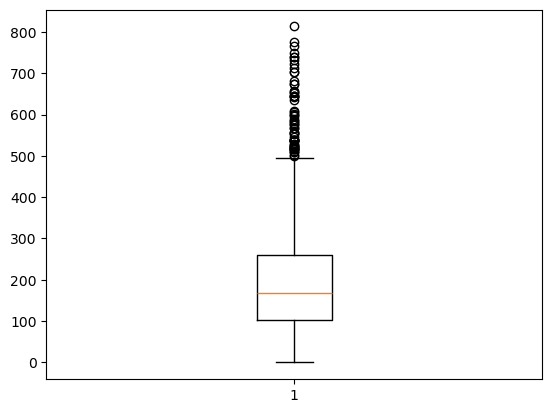

In [128]:
# Draw Boxplot the distribution for column + delete warnings
plt.boxplot(df['num_critic_for_reviews'].dropna())
plt.show()

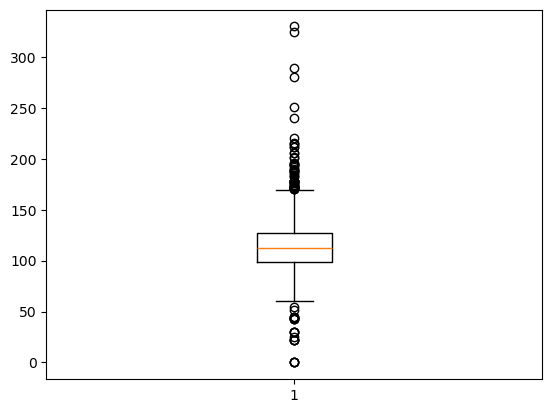

In [130]:
plt.boxplot(df['duration'].dropna())
plt.show()

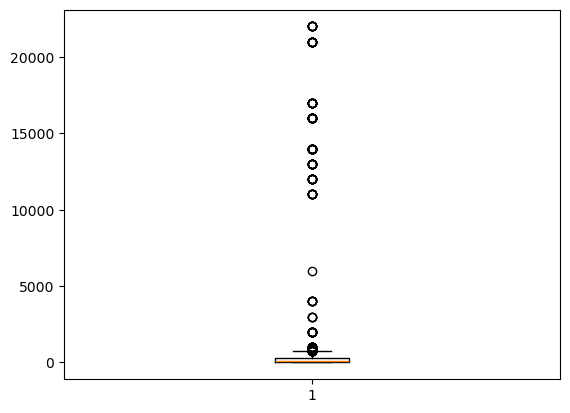

In [132]:
plt.boxplot(df['director_facebook_likes'].dropna())
plt.show()

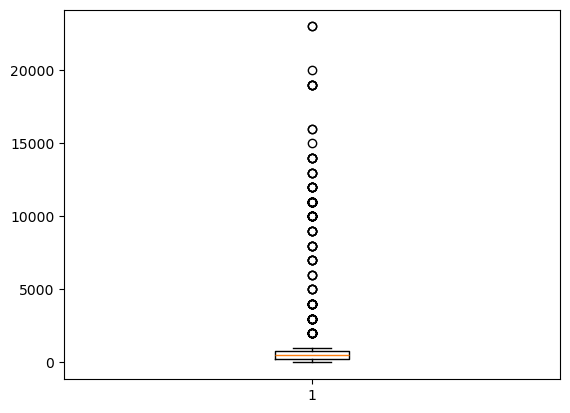

In [134]:
plt.boxplot(df['actor_3_facebook_likes'].dropna())
plt.show()

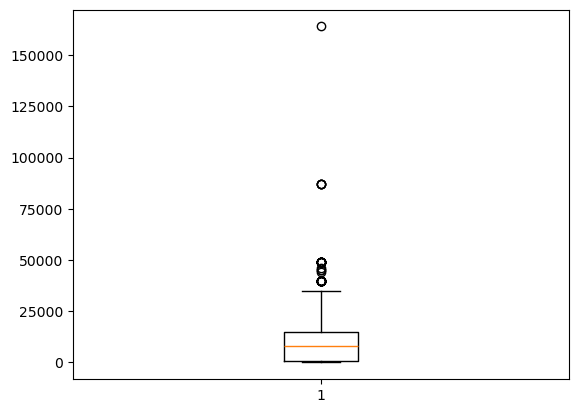

In [136]:
plt.boxplot(df['actor_1_facebook_likes'].dropna())
plt.show()

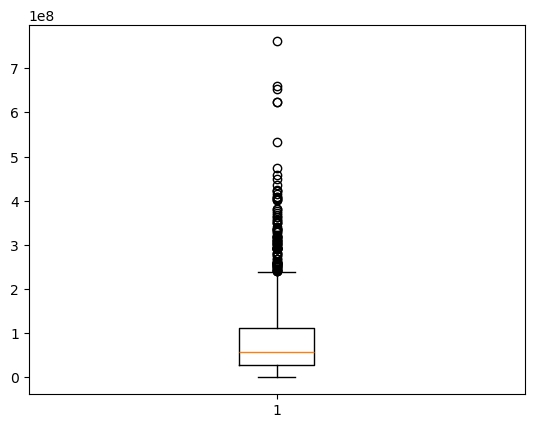

In [138]:
plt.boxplot(df['gross'].dropna())
plt.show()

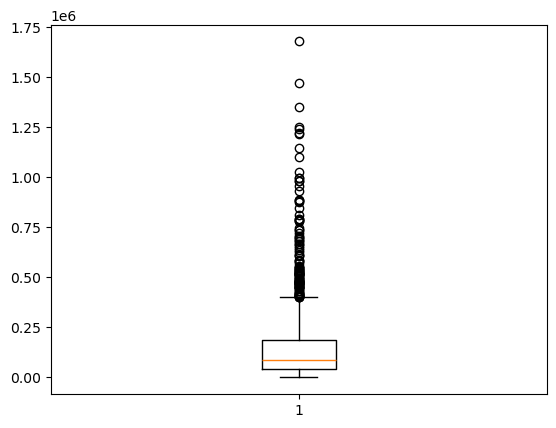

In [140]:
plt.boxplot(df['num_voted_users'].dropna())
plt.show()

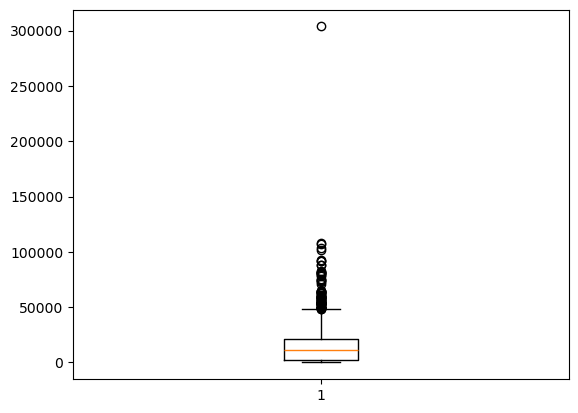

In [142]:
plt.boxplot(df['cast_total_facebook_likes'].dropna())
plt.show()

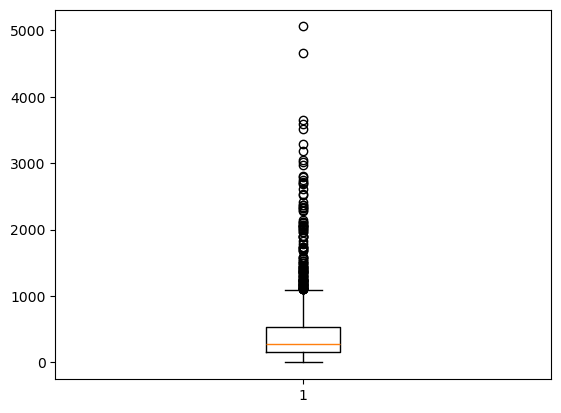

In [144]:
plt.boxplot(df['num_user_for_reviews'].dropna())
plt.show()

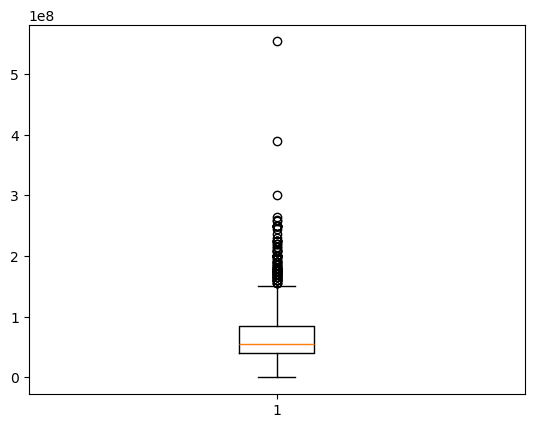

In [146]:
plt.boxplot(df['budget'].dropna())
plt.show()

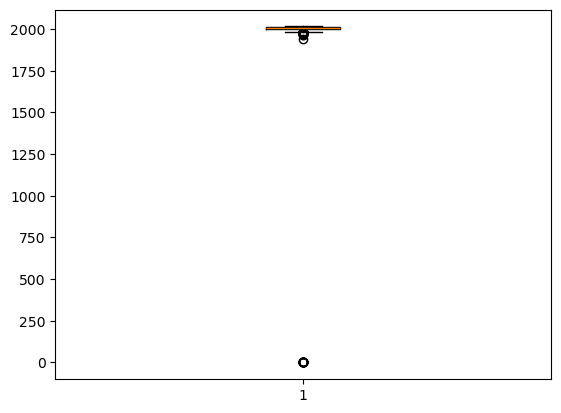

In [148]:
plt.boxplot(df['title_year'].dropna())
plt.show()

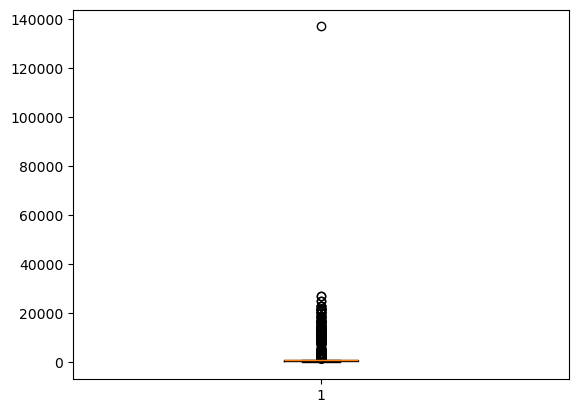

In [150]:
plt.boxplot(df['actor_2_facebook_likes'].dropna())
plt.show()

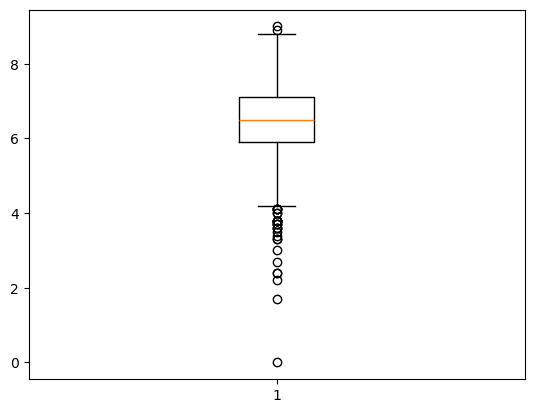

In [152]:
plt.boxplot(df['imdb_score'].dropna())
plt.show()

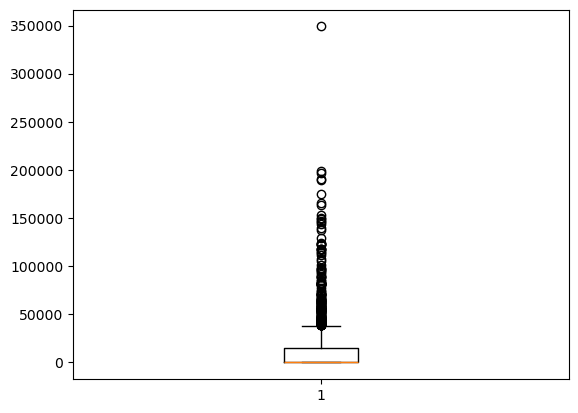

In [154]:
plt.boxplot(df['movie_facebook_likes'].dropna())
plt.show()

### Coefficient of Correlation

In [157]:
# Calculate the coefficient of correlation between director_facebook_likes and actor1_facebook_likes
correlation = df['director_facebook_likes'].corr(df['actor_1_facebook_likes'])
print(f"Coefficient of Correlation between Director Facebook Likes and Actor1 Facebook Likes: {correlation}")

# Calculate the coefficient of correlation between director_facebook_likes and actor2_facebook_likes
correlation = df['director_facebook_likes'].corr(df['actor_2_facebook_likes'])
print(f"Coefficient of Correlation between Director Facebook Likes and Actor2 Facebook Likes: {correlation}")

# Calculate the coefficient of correlation between director_facebook_likes and actor3_facebook_likes
correlation = df['director_facebook_likes'].corr(df['actor_3_facebook_likes'])
print(f"Coefficient of Correlation between Director Facebook Likes and Actor3 Facebook Likes: {correlation}")

# Calculate the coefficient of correlation between director_facebook_likes and cast_total_facebook_likes
correlation = df['director_facebook_likes'].corr(df['cast_total_facebook_likes'])
print(f"Coefficient of Correlation between Director Facebook Likes and Cast Total Facebook Likes: {correlation}")

Coefficient of Correlation between Director Facebook Likes and Actor1 Facebook Likes: 0.13240553876985345
Coefficient of Correlation between Director Facebook Likes and Actor2 Facebook Likes: 0.10884980177116867
Coefficient of Correlation between Director Facebook Likes and Actor3 Facebook Likes: 0.14138585777595863
Coefficient of Correlation between Director Facebook Likes and Cast Total Facebook Likes: 0.15059888481244518


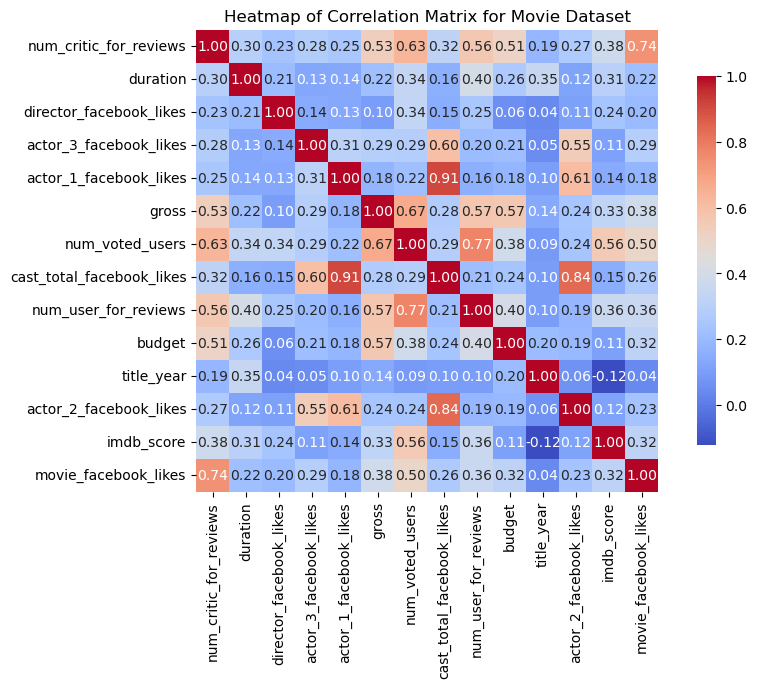

In [159]:
# Select only numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=['float64', 'int64'])

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Set up the matplotlib figure
plt.figure(figsize=(10, 6))

# Create a heatmap with the correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
# Set the title
plt.title('Heatmap of Correlation Matrix for Movie Dataset')

# Show the plot
plt.show()

## Regression

In [162]:
# Definition of variable
y = df["director_facebook_likes"] # Target variable 

X = df[["actor_1_facebook_likes", "actor_2_facebook_likes", "actor_3_facebook_likes", "cast_total_facebook_likes"]]  # Independent Features

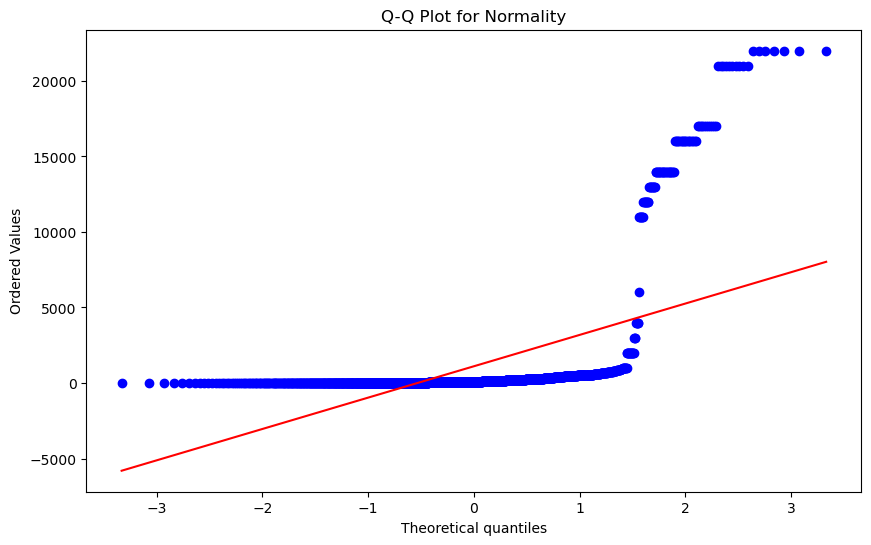

In [164]:
# Q-Q Plot to check normality visually
import scipy.stats as stats

plt.figure(figsize=(10, 6))
stats.probplot(y, dist="norm", plot=plt)
plt.title('Q-Q Plot for Normality')
plt.show()

### Normal Distribution

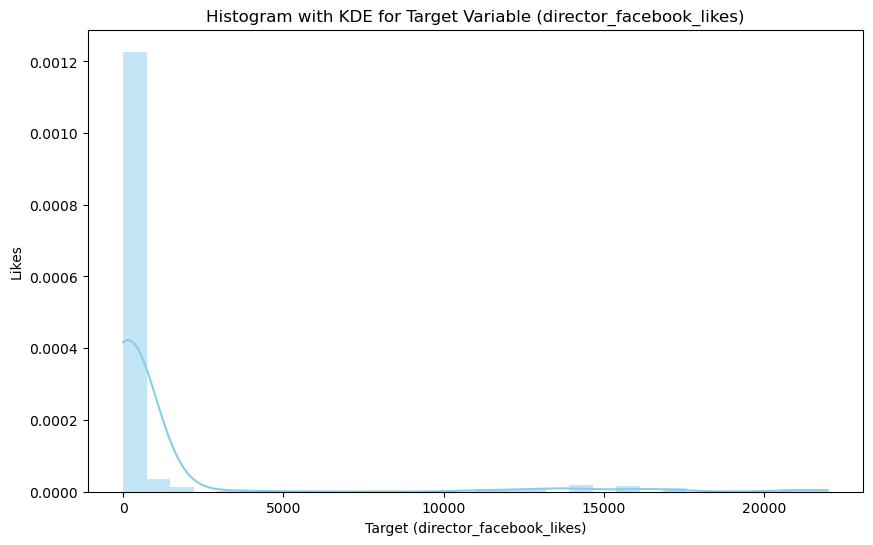

In [166]:
# Plot Histogram with KDE to check normality

plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True, bins=30, color='skyblue', stat='density', linewidth=0)
plt.title('Histogram with KDE for Target Variable (director_facebook_likes)')
plt.xlabel('Target (director_facebook_likes)')
plt.ylabel('Likes')
plt.show()

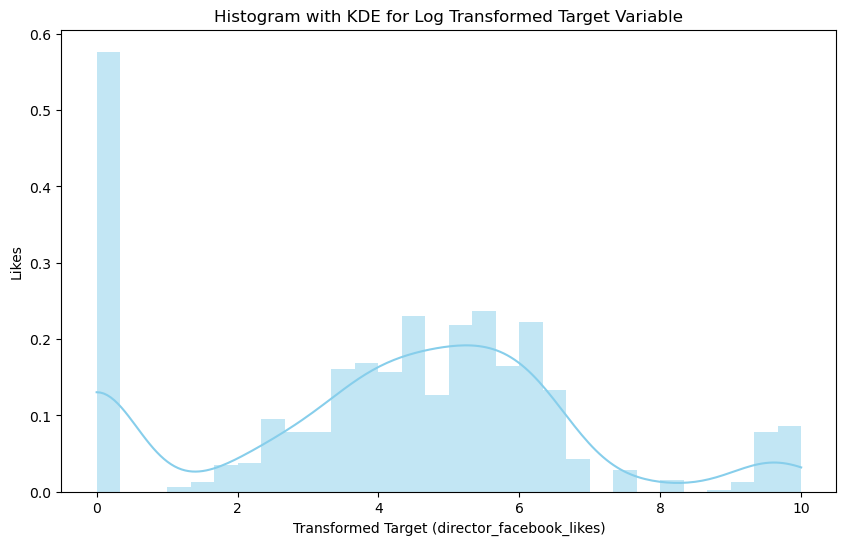

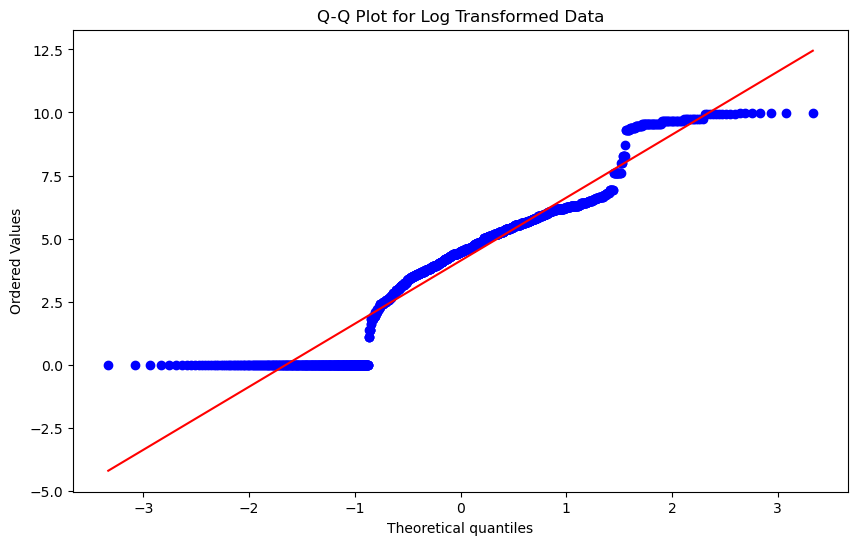

In [168]:
# Log Transformation (only if data is skewed)
# This reduces positive skewness and makes the distribution more normal

y_log = np.log1p(y)  # Log1p handles values that are zero or negative (log(1+x))

# Visualizing the transformed data
plt.figure(figsize=(10, 6))
sns.histplot(y_log, kde=True, bins=30, color='skyblue', stat='density', linewidth=0)
plt.title('Histogram with KDE for Log Transformed Target Variable')
plt.xlabel('Transformed Target (director_facebook_likes)')
plt.ylabel('Likes')
plt.show()

# Q-Q plot after transformation
plt.figure(figsize=(10, 6))
stats.probplot(y_log, dist="norm", plot=plt)
plt.title('Q-Q Plot for Log Transformed Data')
plt.show()

In [170]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.2, random_state=42)

In [172]:
# Step 4: Scale features (important for KNN, Ridge, Lasso)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Linear Regression

In [174]:
# Step 5: Linear Regression Model
lin_reg = LinearRegression()

# Train the model
lin_reg.fit(X_train_scaled, y_train)  # Use scaled data for linear models

# Make predictions
y_pred = lin_reg.predict(X_test_scaled) #y_test original

# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display results
print("Linear Regression - MSE:", mse)
print("Linear Regression - R2:", r2)

Linear Regression - MSE: 6.187559802431029
Linear Regression - R2: 0.02446099013012426


In [176]:
# Step 6: Ridge Regression Model
ridge = Ridge()

# Hyperparameter grid for Ridge (alpha is the regularization parameter)
param_grid_ridge = {'alpha': [0.1, 1, 10, 100]}

# Set up GridSearchCV for Ridge
grid_search_ridge = GridSearchCV(estimator=ridge, param_grid=param_grid_ridge, cv=5, scoring='neg_mean_squared_error')
grid_search_ridge.fit(X_train_scaled, y_train)

# Get the best model
best_ridge = grid_search_ridge.best_estimator_

# Make predictions
y_pred_ridge = best_ridge.predict(X_test_scaled)

# Evaluate the model
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

# Display results
print("Ridge Regression - Best Alpha:", grid_search_ridge.best_params_)
print("Ridge Regression - MSE:", mse_ridge)
print("Ridge Regression - R2:", r2_ridge)

Ridge Regression - Best Alpha: {'alpha': 100}
Ridge Regression - MSE: 6.187249858009789
Ridge Regression - R2: 0.024509856384910766


In [178]:
# Step 7: Lasso Regression Model
lasso = Lasso()

# Hyperparameter grid for Lasso (alpha is the regularization parameter)
param_grid_lasso = {'alpha': [0.1, 1, 10, 100]}

# Set up GridSearchCV for Lasso
grid_search_lasso = GridSearchCV(estimator=lasso, param_grid=param_grid_lasso, cv=5, scoring='neg_mean_squared_error')
grid_search_lasso.fit(X_train_scaled, y_train)

# Get the best model
best_lasso = grid_search_lasso.best_estimator_

# Make predictions
y_pred_lasso = best_lasso.predict(X_test_scaled)

# Evaluate the model
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

# Display results
print("Lasso Regression - Best Alpha:", grid_search_lasso.best_params_)
print("Lasso Regression - MSE:", mse_lasso)
print("Lasso Regression - R2:", r2_lasso)

Lasso Regression - Best Alpha: {'alpha': 0.1}
Lasso Regression - MSE: 6.212939369918573
Lasso Regression - R2: 0.02045961334698665


### Decision Tree Regression

In [180]:
# Step 8: Decision Tree Regression Model
dt = DecisionTreeRegressor(random_state=42)

# Hyperparameter grid for Decision Tree
param_grid_dt = {
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ['absolute_error', 'squared_error']
}

# Set up GridSearchCV for Decision Tree
grid_search_dt = GridSearchCV(estimator=dt, param_grid=param_grid_dt, cv=5, scoring='neg_mean_squared_error')
grid_search_dt.fit(X_train, y_train)

# Get the best model
best_dt = grid_search_dt.best_estimator_

# Make predictions
y_pred_dt = best_dt.predict(X_test)

# Evaluate the model
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)

# Display results
print("Decision Tree - Best Params:", grid_search_dt.best_params_)
print("Decision Tree - MSE:", mse_dt)
print("Decision Tree - R2:", r2_dt)

Decision Tree - Best Params: {'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
Decision Tree - MSE: 7.641281403969106
Decision Tree - R2: -0.20473471497380435


### Random Forest Regression

In [181]:
# Step 9: Random Forest Regression Model
rf = RandomForestRegressor(random_state=42)

# Hyperparameter grid for Random Forest
param_grid_rf = {
    "n_estimators": [50, ],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]

}

# Set up GridSearchCV for Random Forest
grid_search_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, scoring='neg_mean_squared_error')
grid_search_rf.fit(X_train, y_train)

# Get the best model
best_rf = grid_search_rf.best_estimator_

# Make predictions
y_pred_rf = best_rf.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# Display results
print("Random Forest - Best Params:", grid_search_rf.best_params_)
print("Random Forest - MSE:", mse_rf)
print("Random Forest - R2:", r2_rf)


Random Forest - Best Params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}
Random Forest - MSE: 6.309370547733729
Random Forest - R2: 0.0052561440101047685


### K-Nearest Neighbors Regression

In [267]:
# Step 10: K-Nearest Neighbors Regression Model (with Euclidean distance)
knn = KNeighborsRegressor()

# Hyperparameter grid for KNN, use Euclidean distance (p=2) only
param_grid_knn = {
    "n_neighbors": [3, 5, 7, 10],    # Number of neighbors to consider
    "weights": ['uniform', 'distance']  # Uniform weights or weighted by distance
}

# Set up GridSearchCV for KNN
grid_search_knn = GridSearchCV(estimator=knn, param_grid=param_grid_knn, cv=5, scoring='neg_mean_squared_error')
grid_search_knn.fit(X_train_scaled, y_train)

# Get the best model
best_knn = grid_search_knn.best_estimator_

# Make predictions
y_pred_knn = best_knn.predict(X_test_scaled)

# Evaluate the model
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

# Display results
print("KNN Regression (Euclidean) - Best Params:", grid_search_knn.best_params_)
print("KNN Regression - MSE:", mse_knn)
print("KNN Regression - R2:", r2_knn)


KNN Regression (Euclidean) - Best Params: {'n_neighbors': 10, 'weights': 'distance'}
KNN Regression - MSE: 6.925509924534452
KNN Regression - R2: -0.09188521975495578


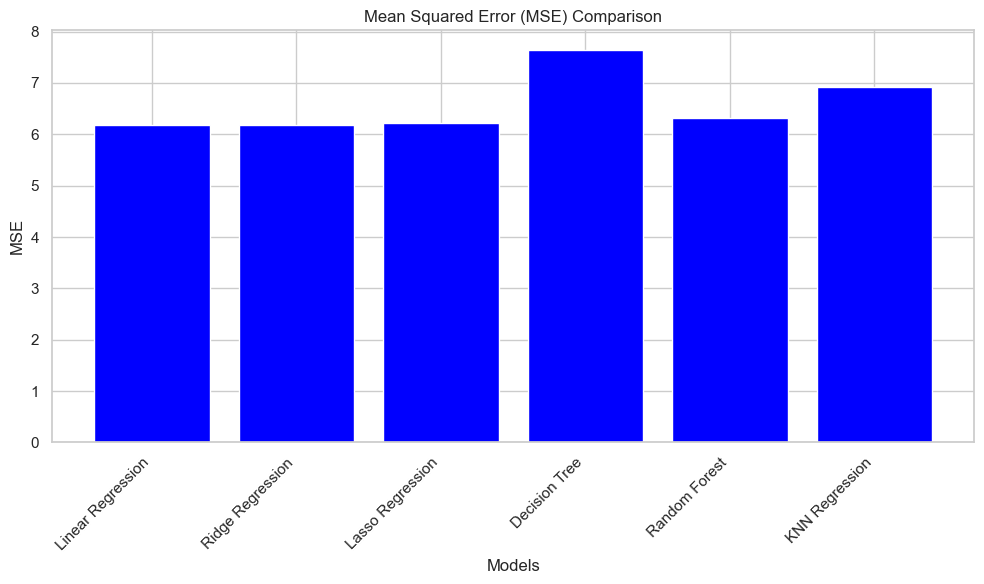

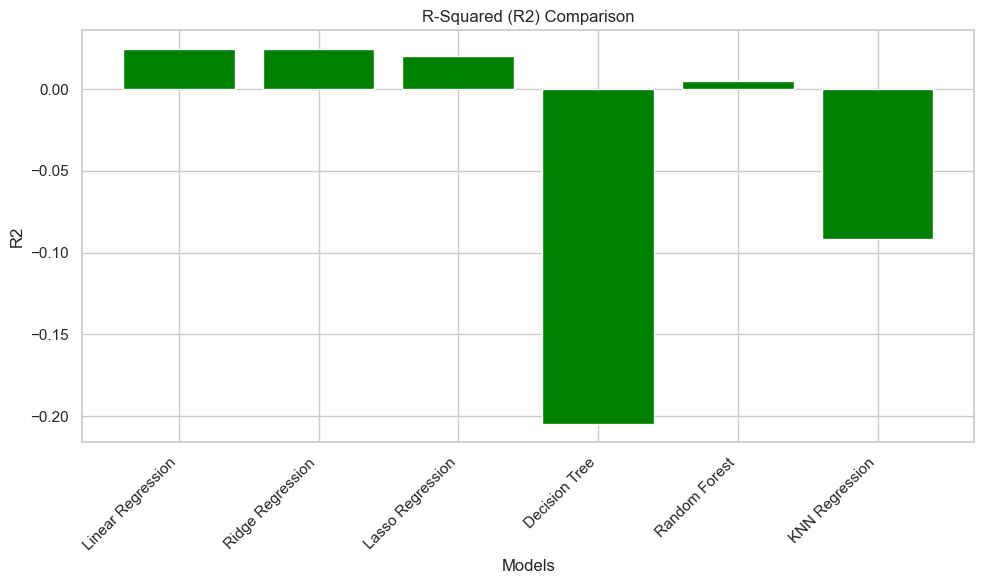

In [269]:
# Step 1: Collect the results in a dictionary
models = ['Linear Regression', 'Ridge Regression', 'Lasso Regression',
          'Decision Tree', 'Random Forest', 'KNN Regression']

mse_values = [mse, mse_ridge, mse_lasso, mse_dt, mse_rf, mse_knn]
r2_values = [r2, r2_ridge, r2_lasso, r2_dt, r2_rf, r2_knn]

# Step 2: Plot MSE
plt.figure(figsize=(10, 6))
plt.bar(models, mse_values, color='blue')
plt.title('Mean Squared Error (MSE) Comparison')
plt.xlabel('Models')
plt.ylabel('MSE')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

# Step 3: Plot R2
plt.figure(figsize=(10, 6))
plt.bar(models, r2_values, color='green')
plt.title('R-Squared (R2) Comparison')
plt.xlabel('Models')
plt.ylabel('R2')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()  # Adjust layout to prevent clipping
plt.show()

### Normal Distribution

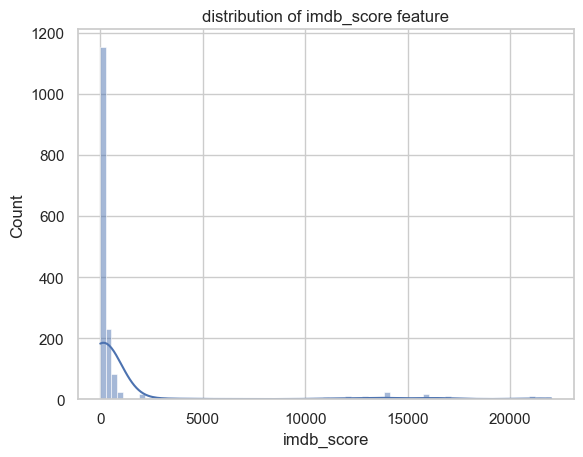

In [289]:
# Check if the data is normally distributed using a histogram
sns.histplot(y,kde=True)
plt.xlabel('imdb_score')
plt.title('distribution of imdb_score feature')
plt.show()

### The 68-95-99.7 empirical rule

### Skewness

In [183]:
# Skewness the distribution 
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        skewness = df[i].skew()
        print(f"Skewness of {i}: {skewness}")

Skewness of num_critic_for_reviews: 1.304073974507767
Skewness of duration: 1.2659332569993027
Skewness of director_facebook_likes: 3.9823703836920052
Skewness of actor_3_facebook_likes: 4.683002477668562
Skewness of actor_1_facebook_likes: 3.157637727752713
Skewness of gross: 2.357847956838364
Skewness of num_voted_users: 3.0783253550773706
Skewness of cast_total_facebook_likes: 4.103115303387973
Skewness of num_user_for_reviews: 3.3478904883080287
Skewness of budget: 2.001113856535498
Skewness of title_year: -7.112456684044213
Skewness of actor_2_facebook_likes: 9.023653591703814
Skewness of imdb_score: -0.5967028913942166
Skewness of movie_facebook_likes: 3.988278549798795


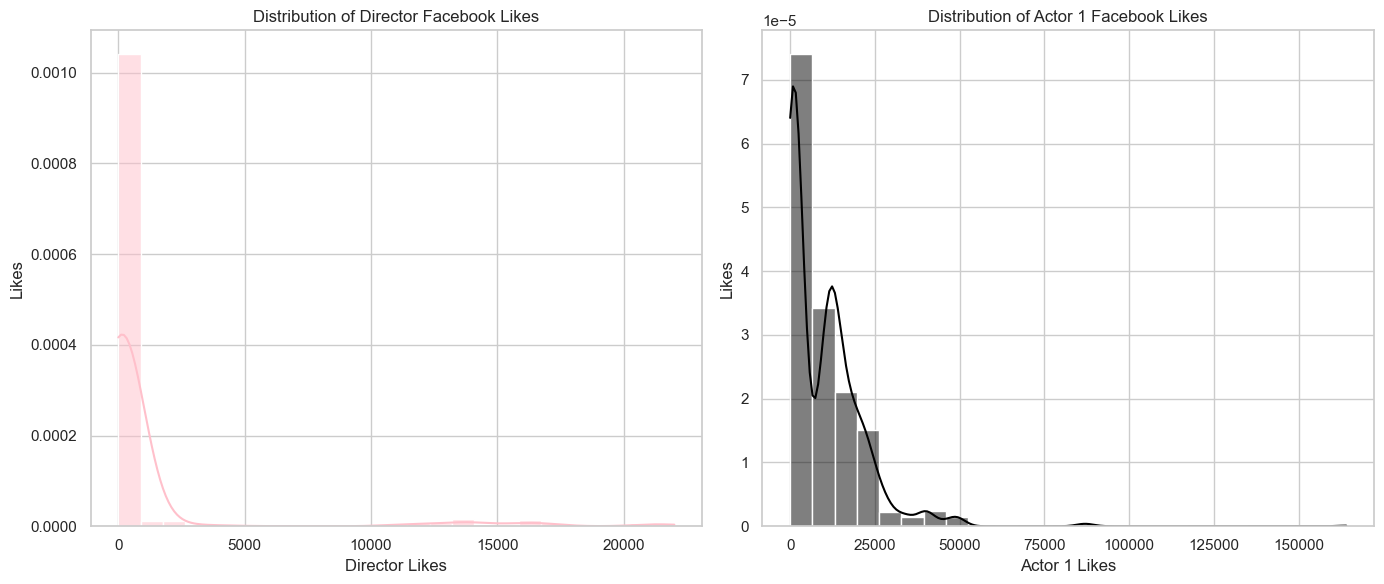

In [184]:
# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for distribution to Director Facebook Likes 
plt.subplot(1, 2, 1)
sns.histplot(df['director_facebook_likes'].dropna(), bins=25, kde=True, color='pink', stat='density')
plt.title('Distribution of Director Facebook Likes')
plt.xlabel('Director Likes')
plt.ylabel('Likes')

# Plot for distribution to Actor 1 Facebook Likes 
plt.subplot(1, 2, 2)
sns.histplot(df['actor_1_facebook_likes'].dropna(), bins=25, kde=True, color='black', stat='density')
plt.title('Distribution of Actor 1 Facebook Likes')
plt.xlabel('Actor 1 Likes')
plt.ylabel('Likes')

plt.tight_layout()
plt.show()

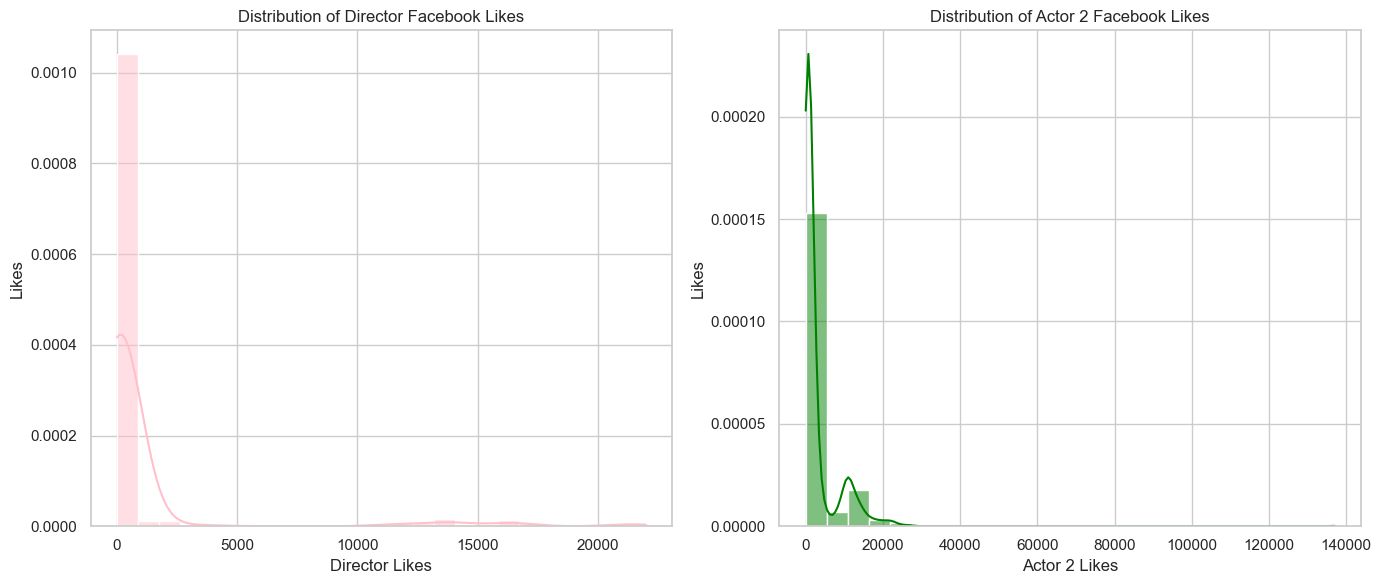

In [186]:
# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for distribution to Director Facebook Likes 
plt.subplot(1, 2, 1)
sns.histplot(df['director_facebook_likes'].dropna(), bins=25, kde=True, color='pink', stat='density')
plt.title('Distribution of Director Facebook Likes')
plt.xlabel('Director Likes')
plt.ylabel('Likes')

# Plot for distribution to Actor 2 Facebook Likes 
plt.subplot(1, 2, 2)
sns.histplot(df['actor_2_facebook_likes'].dropna(), bins=25, kde=True, color='green', stat='density')
plt.title('Distribution of Actor 2 Facebook Likes')
plt.xlabel('Actor 2 Likes')
plt.ylabel('Likes')

plt.tight_layout()
plt.show()

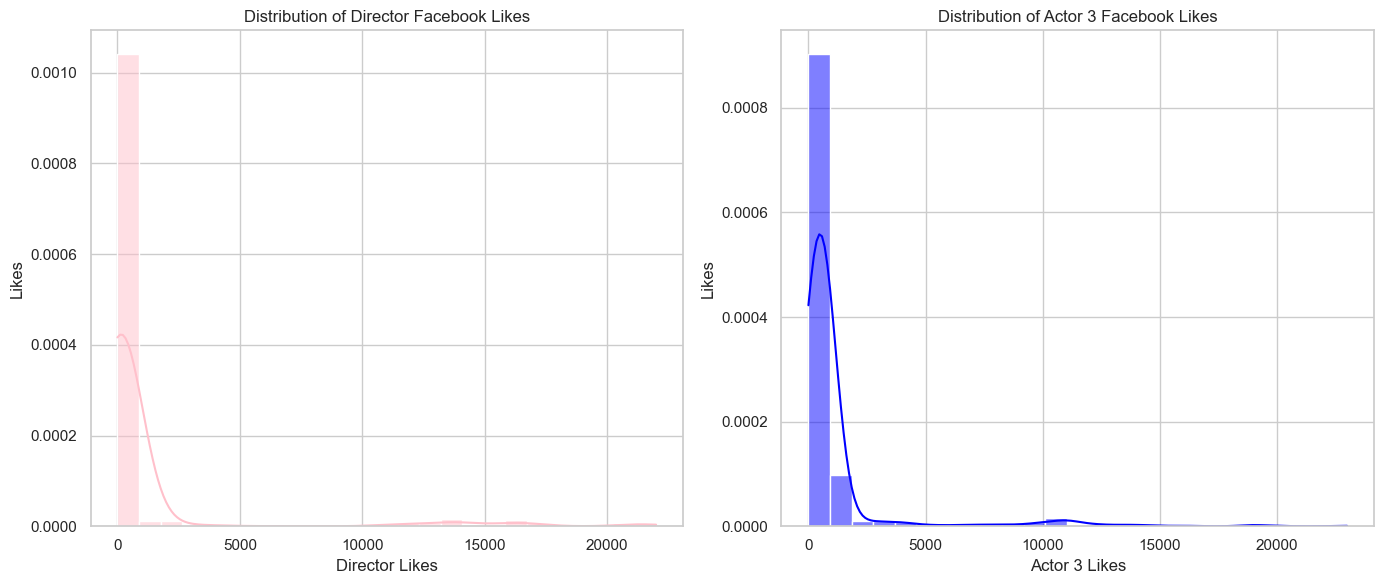

In [187]:
# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for distribution to Director Facebook Likes 
plt.subplot(1, 2, 1)
sns.histplot(df['director_facebook_likes'].dropna(), bins=25, kde=True, color='pink', stat='density')
plt.title('Distribution of Director Facebook Likes')
plt.xlabel('Director Likes')
plt.ylabel('Likes')

# Plot for distribution to Actor 3 Facebook Likes 
plt.subplot(1, 2, 2)
sns.histplot(df['actor_3_facebook_likes'].dropna(), bins=25, kde=True, color='blue', stat='density')
plt.title('Distribution of Actor 3 Facebook Likes')
plt.xlabel('Actor 3 Likes')
plt.ylabel('Likes')

plt.tight_layout()
plt.show()

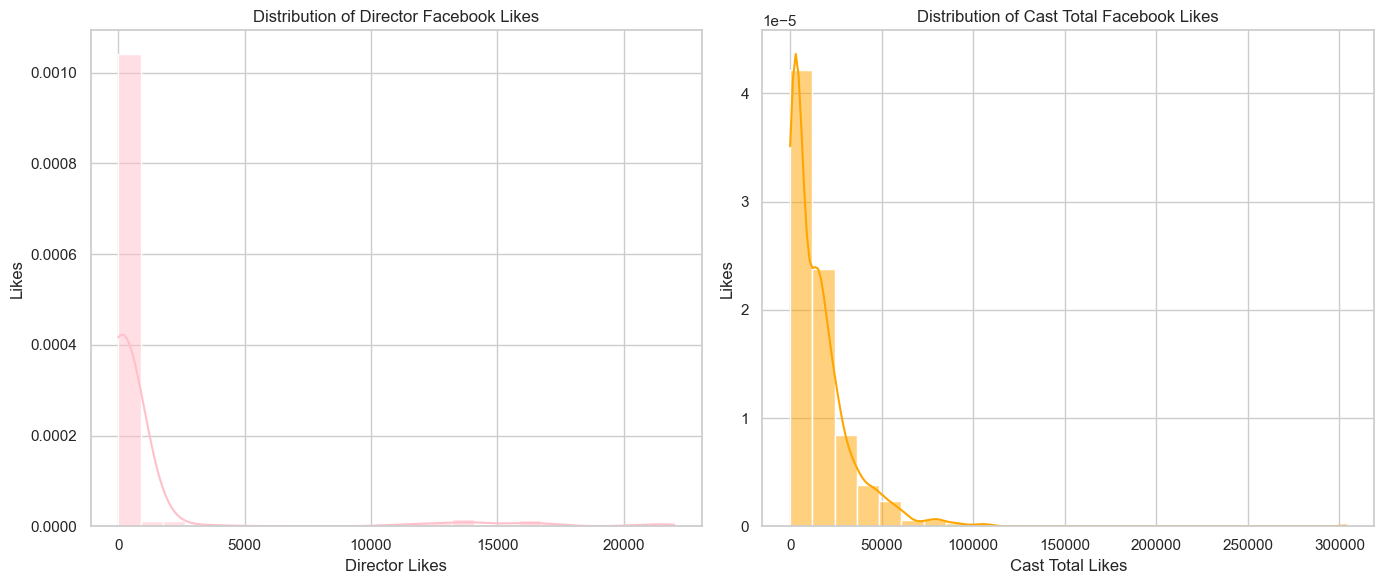

In [188]:
# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for distribution to Director Facebook Likes 
plt.subplot(1, 2, 1)
sns.histplot(df['director_facebook_likes'].dropna(), bins=25, kde=True, color='pink', stat='density')
plt.title('Distribution of Director Facebook Likes')
plt.xlabel('Director Likes')
plt.ylabel('Likes')

# Plot for distribution to Cast Total Facebook Likes 
plt.subplot(1, 2, 2)
sns.histplot(df['cast_total_facebook_likes'].dropna(), bins=25, kde=True, color='orange', stat='density')
plt.title('Distribution of Cast Total Facebook Likes')
plt.xlabel('Cast Total Likes')
plt.ylabel('Likes')

plt.tight_layout()
plt.show()

### Kurtosis

In [190]:
# Kurtosis the distribution 
for i in cols:
    if df[i].dtype == 'object':
        continue
    else:
        kurtosis = df[i].kurt()
        print(f"Kurtosis of {i}: {kurtosis}")

Kurtosis of num_critic_for_reviews: 2.0343845360043438
Kurtosis of duration: 9.051901772710712
Kurtosis of director_facebook_likes: 14.958381445728246
Kurtosis of actor_3_facebook_likes: 23.941543699841205
Kurtosis of actor_1_facebook_likes: 26.211877324098168
Kurtosis of gross: 8.506084517919874
Kurtosis of num_voted_users: 13.728201294187084
Kurtosis of cast_total_facebook_likes: 45.149726672500336
Kurtosis of num_user_for_reviews: 16.369480118303287
Kurtosis of budget: 8.27129874604241
Kurtosis of title_year: 48.691104532420205
Kurtosis of actor_2_facebook_likes: 182.19490719792665
Kurtosis of imdb_score: 1.6594551364249148
Kurtosis of movie_facebook_likes: 25.220112277580885


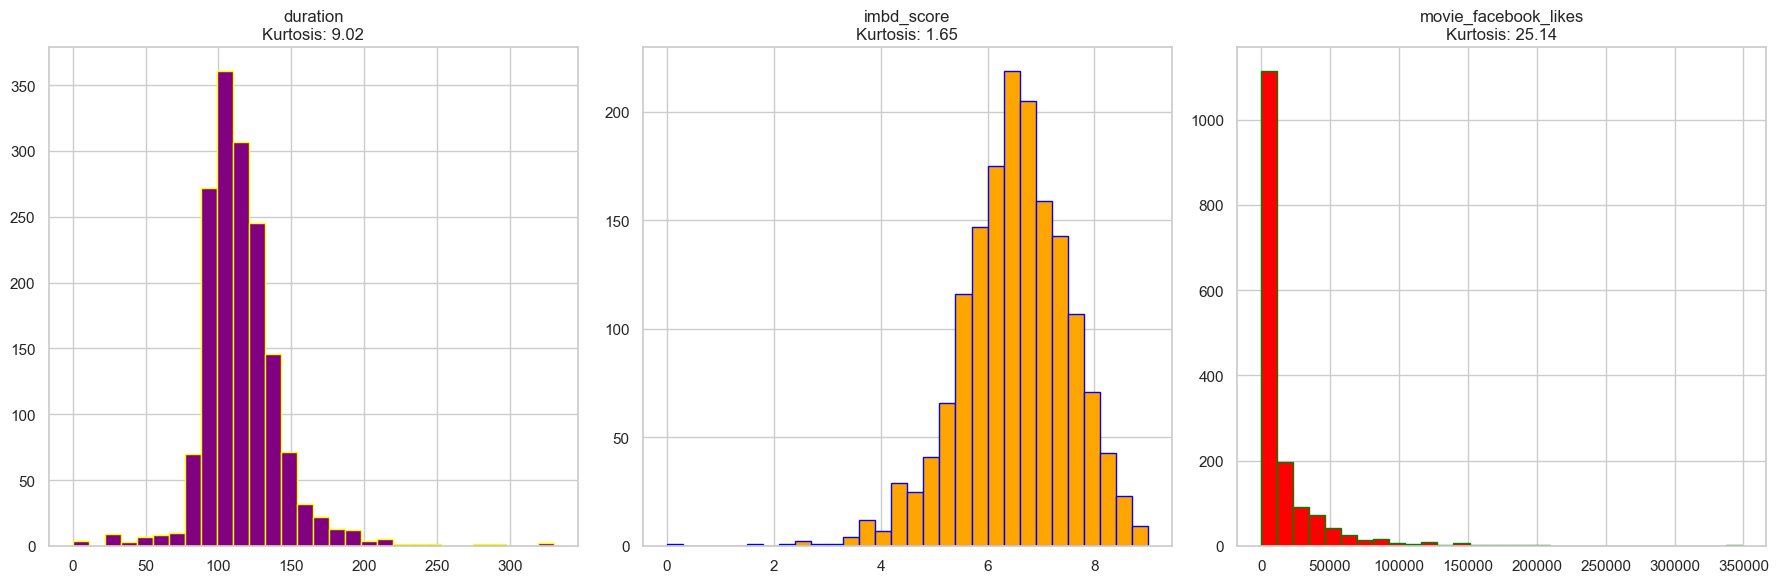

duration Kurtosis: 9.02
imdb_score Kurtosis: 1.65
movie_fcebook_likes Kurtosis: 25.14


In [191]:
# Clean 0 and definite the columns
col1 = df["duration"].dropna()
col2 = df["imdb_score"].dropna()
col3 = df["movie_facebook_likes"].dropna()

#Calculate Kurtosis
normal_data = np.random.normal(0, 1, 1000)
leptokurtic_data = np.random.standard_t(2, 1000)
platykurtic_data = np.random.uniform(-2, 2, 1000)

kurt_col1 = stats.kurtosis(col1, fisher=True)
kurt_col2 = stats.kurtosis(col2, fisher=True)
kurt_col3 = stats.kurtosis(col3, fisher=True)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].hist(col1, bins=30, color='purple', edgecolor='yellow')
axes[0].set_title(f'duration\nKurtosis: {kurt_col1:.2f}')

axes[1].hist(col2, bins=30, color='orange', edgecolor='blue')
axes[1].set_title(f'imbd_score\nKurtosis: {kurt_col2:.2f}')

axes[2].hist(col3, bins=30, color='red', edgecolor='green')
axes[2].set_title(f'movie_facebook_likes\nKurtosis: {kurt_col3:.2f}')

plt.tight_layout()
plt.show()

print(f"duration Kurtosis: {kurt_col1:.2f}")
print(f"imdb_score Kurtosis: {kurt_col2:.2f}")
print(f"movie_fcebook_likes Kurtosis: {kurt_col3:.2f}")


### Percentage

In [193]:
#Sum of the facebook_likes on actor roles
Total = (1128.0613535736875  #director
        + 9776.698817672683  #actor 1
        + 2874.4825653798257 #actor 2
        + 1119.8660436137072) #actor 3 / total =  14899.1087802399

In [196]:
#Percentage of likes per director, actor 1,2,3
#Add the total of likes base n the mean

#Director_facebook_likes percentage
Mean_of_director_facebook_likes_percentage = 1128.0613535736875
Total = 14899.1087802399
director_facebook_likes_percentage = (Mean_of_director_facebook_likes_percentage / Total) * 100
print(f'Percentage Director Facebook likes: {Mean_of_director_facebook_likes_percentage}%')

#Actor1_facebook_likes percentage
Mean_of_actor1_facebook_likes_percentage = 9776.698817672683
Total = 14899.1087802399
actor1_facebook_likes_percentage = (Mean_of_actor1_facebook_likes_percentage / Total) * 100
print(f'Percentage Actor 1 Facebook likes: {Mean_of_actor1_facebook_likes_percentage}%')

#Actor2_facebook_likes percentage
Mean_of_actor2_facebook_likes_percentage = 2874.4825653798257
Total = 14899.1087802399
actor2_facebook_likes_percentage = (Mean_of_actor2_facebook_likes_percentage / Total) * 100
print(f'Percentage Actor 2 Facebook likes: {Mean_of_actor2_facebook_likes_percentage}%')

#Actor3_facebook_likes percentage
Mean_of_actor3_facebook_likes_percentage = 1119.8660436137072
Total = 14899.1087802399
actor3_facebook_likes_percentage = (Mean_of_actor3_facebook_likes_percentage / Total) * 100
print(f'Percentage Actor 3 Facebook likes: {Mean_of_actor3_facebook_likes_percentage}%')

#Cast_total_facebook_likes percentage
Mean_of_cast_total_facebook_likes_percentage = 1119.8660436137072
Total = 14899.1087802399
cast_total_facebook_likes_percentage = (Mean_of_cast_total_facebook_likes_percentage / Total) * 100
print(f'Percentage Cast Total Facebook likes: {Mean_of_cast_total_facebook_likes_percentage}%')

Percentage Director Facebook likes: 1128.0613535736875%
Percentage Actor 1 Facebook likes: 9776.698817672683%
Percentage Actor 2 Facebook likes: 2874.4825653798257%
Percentage Actor 3 Facebook likes: 1119.8660436137072%
Percentage Cast Total Facebook likes: 1119.8660436137072%


### Percentile

In [201]:
# 90th Director likes percentile 
p90_director = df['director_facebook_likes'].quantile(0.90)
print(f"Director Facebook Likes - 90th Percentile: {p90_director}")

p90_actor1 = df["actor_1_facebook_likes"].quantile(0.90)
print(f"Actor1 Facebook Likes - 90th Percentile: {p90_actor1}")

# 90th Actor2 likes percentile
p90_actor2 = df["actor_2_facebook_likes"].quantile(0.90)
print(f"Actor2 Facebook Likes - 90th Percentile: {p90_actor2}")

# 90th Actor3 likes percentile
p90_actor3 = df["actor_3_facebook_likes"].quantile(0.90)
print(f"Actor3 Facebook Likes - 90th Percentile: {p90_actor3}")

# 90th Cast total likes percentile
p90_cast_total = df["cast_total_facebook_likes"].quantile(0.90)
print(f"Cast Total Facebook Likes - 90th Percentile: {p90_cast_total}")

Director Facebook Likes - 90th Percentile: 724.3999999999992
Actor1 Facebook Likes - 90th Percentile: 22000.0
Actor2 Facebook Likes - 90th Percentile: 11000.0
Actor3 Facebook Likes - 90th Percentile: 1000.0
Cast Total Facebook Likes - 90th Percentile: 36076.2


### Outliers using Z-Score

In [205]:
#Delete 0 values
director_facebook_likes = df['director_facebook_likes'].dropna()
actor1_facebook_likes = df['actor_1_facebook_likes'].dropna()
actor2_facebook_likes = df['actor_2_facebook_likes'].dropna()
actor3_facebook_likes = df['actor_3_facebook_likes'].dropna()
cast_total_facebook_likes = df['cast_total_facebook_likes'].dropna()

#Director Facebook likes calculated the Z-Score and filter the register where Z-Score is > 3 or < 3 and Outliers
z_scores_director_facebook_likes = stats.zscore(director_facebook_likes)
outliers_zscore_director_facebook_likes = director_facebook_likes[(z_scores_director_facebook_likes > 3) | (z_scores_director_facebook_likes < -3)]

#Actor 1 Facebook likes calculated the Z-Score and filter the register where Z-Score is > 3 or < 3 and Outliers
z_scores_actor1_facebook_likes = stats.zscore(actor1_facebook_likes)
outliers_zscore_actor1_facebook_likes = actor1_facebook_likes[(z_scores_actor1_facebook_likes > 3) | (z_scores_actor1_facebook_likes < -3)]

#Actor 2 Facebook likes calculated the Z-Score and filter the register where Z-Score is > 3 or < 3 and Outliers
z_scores_actor2_facebook_likes = stats.zscore(actor2_facebook_likes)
outliers_zscore_actor2_facebook_likes = actor2_facebook_likes[(z_scores_actor2_facebook_likes > 3) | (z_scores_actor2_facebook_likes < -3)]

#Actor 3 Facebook likes calculated the Z-Score and filter the register where Z-Score is > 3 or < 3 and Outliers
z_scores_actor3_facebook_likes = stats.zscore(actor3_facebook_likes)
outliers_zscore_actor3_facebook_likes = actor3_facebook_likes[(z_scores_actor3_facebook_likes > 3) | (z_scores_actor3_facebook_likes < -3)]

#Cast total Facebook likes calculated the Z-Score and filter the register where Z-Score is > 3 or < 3 and Outliers
z_scores_cast_total_facebook_likes = stats.zscore(cast_total_facebook_likes)
outliers_zscore_cast_total_facebook_likes = cast_total_facebook_likes[(z_scores_cast_total_facebook_likes > 3)| (z_scores_cast_total_facebook_likes < -3)]

print(f"Director_facebook_likes - Outliers based on Z-Score: {outliers_zscore_director_facebook_likes}")
print(f"Actor1_facebook_likes - Outliers based on Z-Score: {outliers_zscore_actor1_facebook_likes}")
print(f"Actor2_facebook_likes - Outliers based on Z-Score: {outliers_zscore_actor2_facebook_likes}")
print(f"Actor3_facebook_likes - Outliers based on Z-Score: {outliers_zscore_actor3_facebook_likes}")
print(f"Cast_Total_facebook_likes - Outliers based on Z-Score: {outliers_zscore_cast_total_facebook_likes}")

Director_facebook_likes - Outliers based on Z-Score: 3       22000
33      13000
48      14000
54      14000
66      22000
        ...  
1556    14000
1562    17000
1600    21000
1603    16000
1604    16000
Name: director_facebook_likes, Length: 79, dtype: Int64
Actor1_facebook_likes - Outliers based on Z-Score: 38       44000
74       87000
105      87000
122      49000
175      49000
200      49000
250      49000
385      49000
397      49000
464      49000
485      49000
555      87000
589      49000
706      46000
933      49000
972      87000
999      45000
1028     49000
1223    164000
1399     45000
1431     49000
1433     49000
1550     49000
Name: actor_1_facebook_likes, dtype: Int64
Actor2_facebook_likes - Outliers based on Z-Score: 3        23000
8        21000
17       21000
33       25000
45       23000
47       22000
97       27000
103      22000
106      25000
179      27000
207      22000
289      23000
619      22000
761      22000
794      21000
933      22000
1185   

# Discrete Distribution

## Binomial Distribution

## Poisson Distribution

## Central Limit Theorem (CLT)

In [230]:
#Define facebook likes parameter
director_facebook_likes_mean = 1128.0613535736875
director_facebook_likes_std = 3750.2515259991123
sample_size = 10
num_samples = 1000

actor_1_facebook_likes_mean = 9776.698817672683
actor_1_facebook_likes_std = 11382.197686496578
sample_size = 10
num_samples = 1000

actor_2_facebook_likes_mean = 2874.4825653798257
actor_2_facebook_likes_std = 5776.938315810571
sample_size = 10
num_samples = 1000

actor_3_facebook_likes_mean = 1119.8660436137072
actor_3_facebook_likes_std = 2568.8520401852074
sample_size = 10
num_samples = 1000

cast_total_facebook_likes_mean = 15042.782202862476
cast_total_facebook_likes_std = 17862.84452977049
sample_size = 10
num_samples = 1000

In [232]:
#Generate non-normal director_facebook_likes (e.g., exponential distribution)
director_facebook_likes = np.random.exponential(scale=director_facebook_likes_std, size=10000)

#Generate non-normal actor_1_facebook_likes (e.g., exponential distribution)
actor_1_facebook_likes = np.random.exponential(scale=actor_1_facebook_likes_std, size=10000)

#Generate non-normal actor_2_facebook_likes (e.g., exponential distribution)
actor_2_facebook_likes = np.random.exponential(scale=actor_2_facebook_likes_std, size=10000)

#Generate non-normal actor_3_facebook_likes (e.g., exponential distribution)
actor_3_facebook_likes = np.random.exponential(scale=actor_3_facebook_likes_std, size=10000)

#Generate non-normal cast_total_facebook_likes (e.g., exponential distribution)
cast_total_facebook_likes = np.random.exponential(scale=cast_total_facebook_likes_std, size=10000)

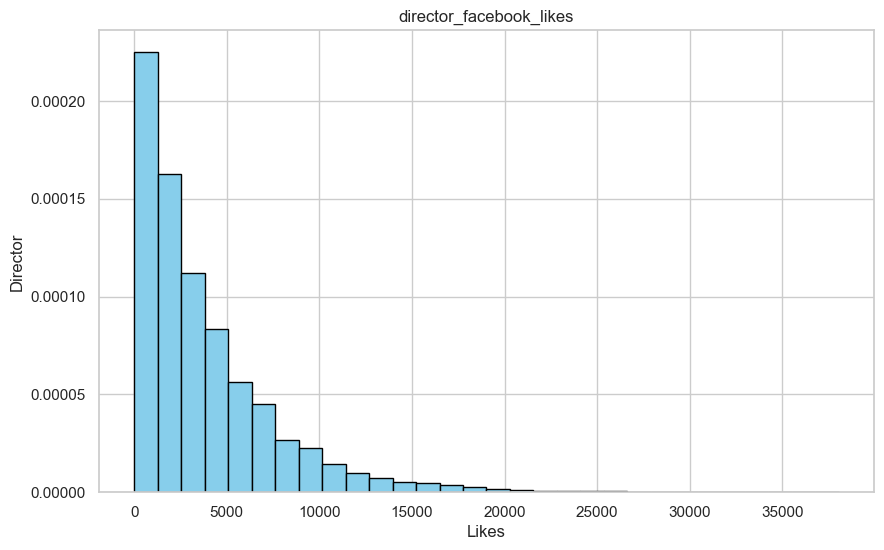

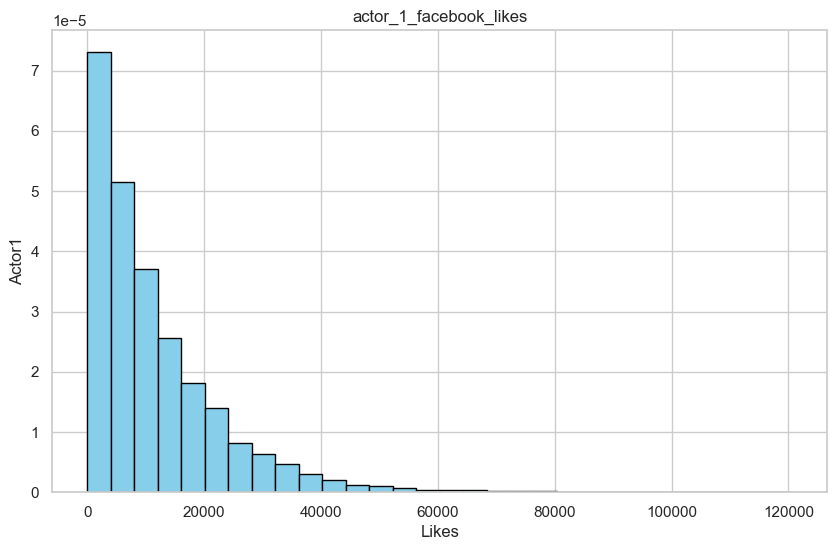

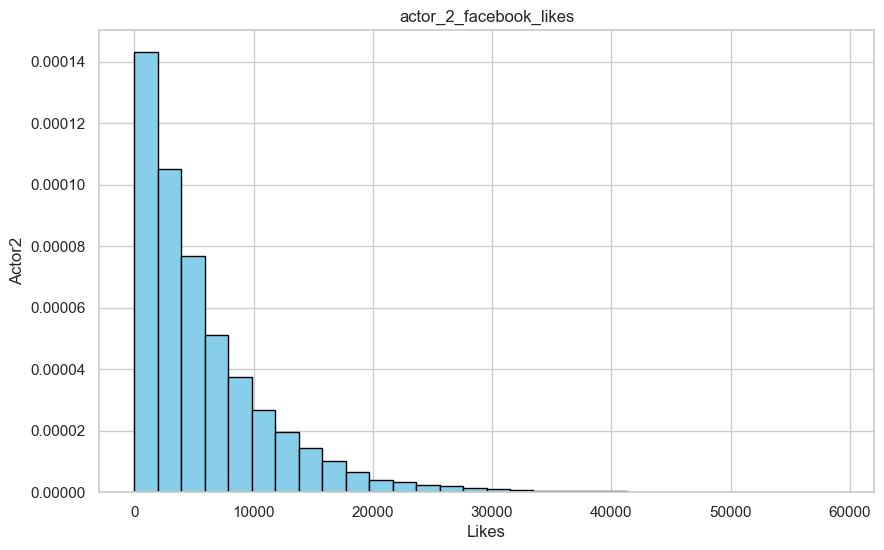

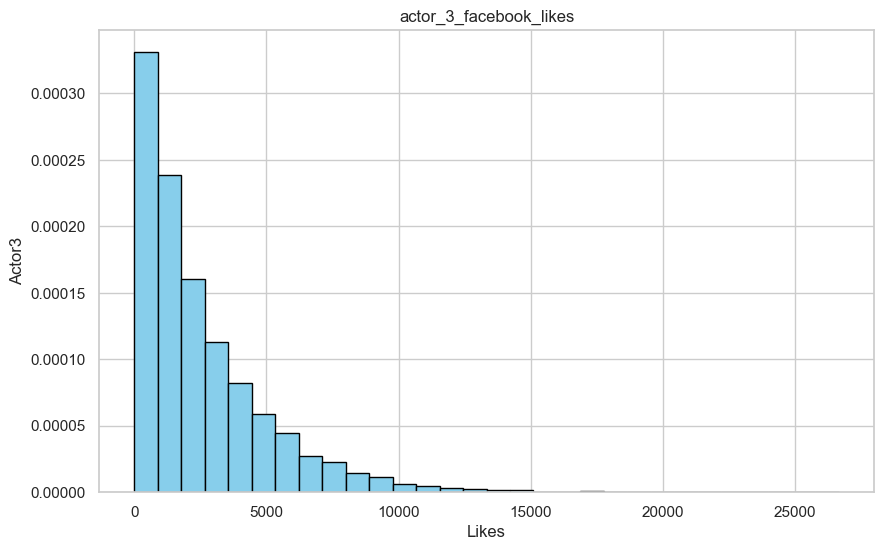

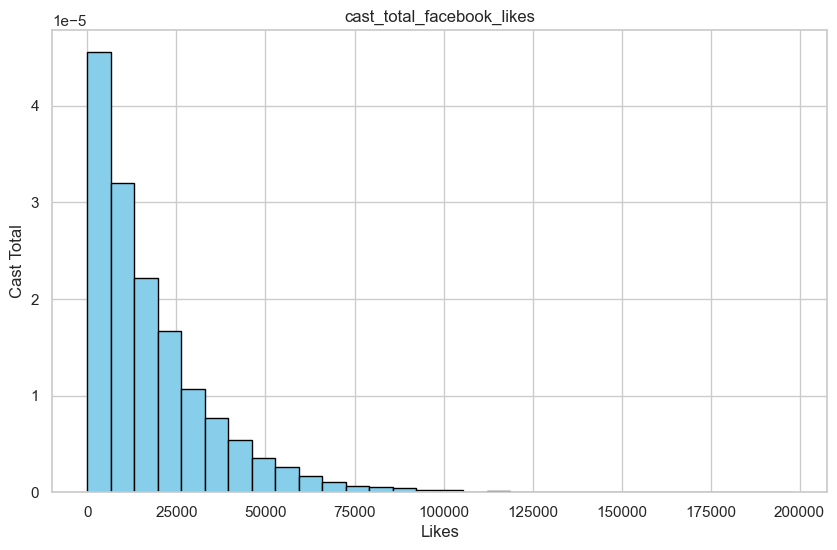

In [234]:
# Plot the distribution of the facebook likes data
plt.figure(figsize=(10, 6))
plt.hist(director_facebook_likes, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('director_facebook_likes')
plt.xlabel('Likes')
plt.ylabel('Director')

plt.figure(figsize=(10, 6))
plt.hist(actor_1_facebook_likes, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('actor_1_facebook_likes')
plt.xlabel('Likes')
plt.ylabel('Actor1')

plt.figure(figsize=(10, 6))
plt.hist(actor_2_facebook_likes, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('actor_2_facebook_likes')
plt.xlabel('Likes')
plt.ylabel('Actor2')

plt.figure(figsize=(10, 6))
plt.hist(actor_3_facebook_likes, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('actor_3_facebook_likes')
plt.xlabel('Likes')
plt.ylabel('Actor3')

plt.figure(figsize=(10, 6))
plt.hist(cast_total_facebook_likes, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('cast_total_facebook_likes')
plt.xlabel('Likes')
plt.ylabel('Cast Total')
plt.show()

x=df['director_facebook_likes'].dropna()
x.shape

x=df['actor_1_facebook_likes'].dropna()
x.shape

Text(0, 0.5, 'Likes')

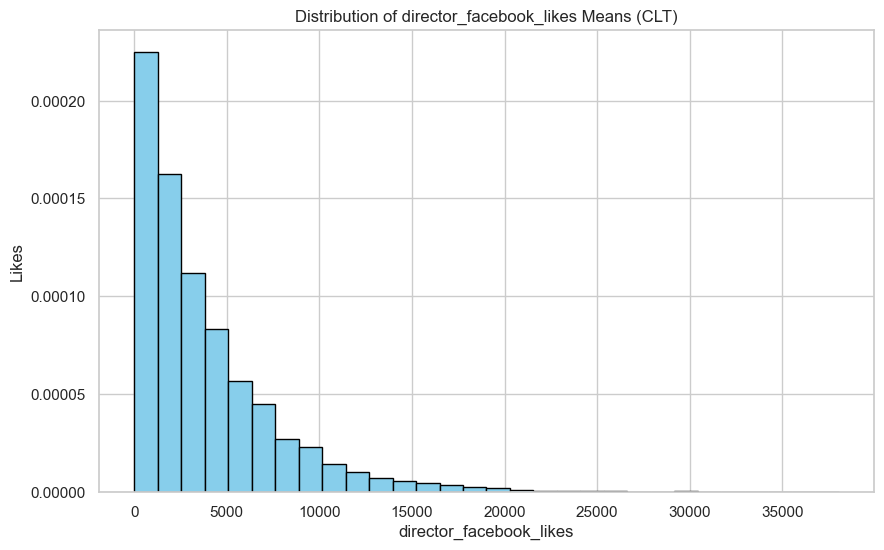

In [236]:
#Plot distribution of facebook likes mean
plt.figure(figsize=(10, 6))
plt.hist(director_facebook_likes, bins=30, density=True, color='skyblue', edgecolor='black')
plt.title('Distribution of director_facebook_likes Means (CLT)')
plt.xlabel('director_facebook_likes')
plt.ylabel('Likes')

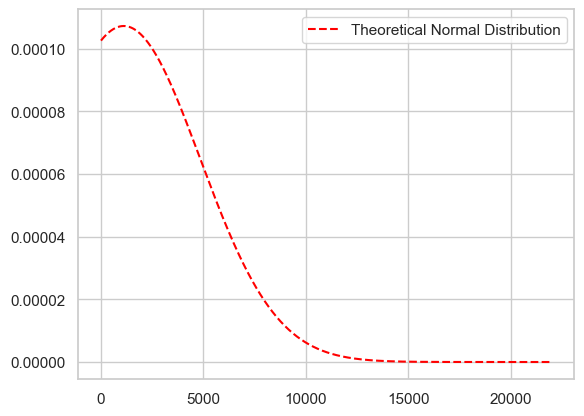

In [256]:
# Calculate director facebook likes mean and standard deviation
data_director = df['director_facebook_likes'].dropna()
mean_director = df['director_facebook_likes'].mean()
std_director = df['director_facebook_likes'].std()

mean_director = np.mean(mean_director)
std_dirrector = np.std(std_director )

# Plot the theoretical normal distribution
x = np.linspace(min(data_director), max(data_director), 1000)
normal_dist = (1 / (std_director * np.sqrt(2 * np.pi))) * np.exp(-(x - mean_director) ** 2 / (2 * std_director ** 2))
plt.plot(x, normal_dist, color='red', linestyle='--', label='Theoretical Normal Distribution')

plt.legend()
plt.show()